# Semana 13 — Interpretabilidad

Se reconstruye LightGBM con la configuración final congelada, muestreo del 50 % mensual,
semilla 42 y 1710 árboles.
Los datos son los Parquet oficiales referenciados en `src/data.py`.

**Etapa 1:** entorno, datos, entrenamiento y guardado en Drive.
**Etapa 2:** control de reproducción en junio. Si falla, detenerse y revisar la causa.
**Etapa 3:** importancia, SHAP, errores por segmentos e informe con resultados de esta ejecución.

El preprocesamiento usa bloques y una matriz float64 en disco. Esto reduce el consumo de RAM;
no garantiza un tiempo de ejecución o memoria máxima. El entrenamiento puede ser prolongado en CPU.
No cambies el muestreo, los hiperparámetros ni las tolerancias a partir de los resultados de junio.

## 1. Obtener la rama de trabajo
Se usa una carpeta nueva para no modificar `/content/proy-machine`, creada en los pasos anteriores.
Esta celda lee GitHub; no hace commits ni push. Si ya existe la carpeta, conserva su versión local.

In [1]:
from pathlib import Path
import subprocess
import os
import sys

REPO_DIR = Path('/content/proy-machine-s13')
REPO_URL = 'https://github.com/A-Joacox/proy-machine.git'
RAMA = 'semana-13'
if not REPO_DIR.exists():
    subprocess.run(['git', 'clone', '--branch', RAMA, '--single-branch', REPO_URL, str(REPO_DIR)], check=True)
if not (REPO_DIR / '.git').is_dir():
    raise RuntimeError('La carpeta de trabajo no es un repositorio Git.')
os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
for args in [['git', 'log', '-1', '--oneline'], ['git', 'branch', '--show-current']]:
    print(subprocess.check_output(args, text=True).strip())
for name in ['src/interpretabilidad.py', 'requirements.txt']:
    if not (REPO_DIR / name).exists():
        raise FileNotFoundError(f'Primero sube {name} a la rama semana-13 de GitHub.')

51d8ed2 Add files via upload
semana-13


## 2. Instalar el entorno comprobado
Estas versiones se usan para esta reconstrucción; no se afirma que sean las versiones originales de semana 12.
Si Colab pide reiniciar la sesión tras instalar, hazlo y vuelve a ejecutar desde la sección 1.
La celda siguiente detecta librerías antiguas que hayan quedado cargadas en memoria.

In [2]:
%pip install -q -r /content/proy-machine-s13/requirements.txt

In [3]:
import importlib
import importlib.metadata

for package, module in [('numpy','numpy'), ('pandas','pandas'), ('scipy','scipy'),
                        ('scikit-learn','sklearn'), ('lightgbm','lightgbm'),
                        ('pyarrow','pyarrow'), ('shap','shap'), ('joblib','joblib'),
                        ('matplotlib','matplotlib')]:
    loaded = importlib.import_module(module)
    installed = importlib.metadata.version(package)
    if loaded.__version__ != installed:
        raise RuntimeError(f'{package}: reinicia la sesión de Colab y vuelve a ejecutar desde la sección 1.')
    print(f'{package}: {installed}')

numpy: 2.3.5
pandas: 2.2.3
scipy: 1.17.0
scikit-learn: 1.8.0
lightgbm: 4.7.0
pyarrow: 26.0.1
shap: 0.54.1
joblib: 1.5.3
matplotlib: 3.10.8


## 3. Confirmar la base de semana 12 y los recursos
Se verifican los hashes de los cinco archivos de partida leídos del ZIP. Una diferencia detiene la
reproducción para no mezclar configuraciones. Los resultados viejos de semana 13 no se consultan.

In [4]:
import json
import hashlib
import psutil
import shutil
import numpy as np
import pandas as pd

EXPECTED_HASHES = {'src/data.py': '4259180c087d865ebd2c803e21ad0f5add97b8bea434bd19b56a1152b7d64ab4', 'src/features.py': 'e1045f83b0d2a5fb0fbc4ea95879761d4d9bd7e179d9e3a8bd6b92ab526a85fd', 'outputs/config_modelo_final.json': '9ed5e35043515ae318c7aa6bce36126bfca206d67119f8e3b1436526822510a3', 'outputs/metrics_evaluacion_final.json': 'ac95cad610eefe73b34d61af5d14389bdd96cf231aeba612aaf5975dcba78ded', 'data/Taxi_Zone_Lookup.csv': '1a99e105092230f8620f301edcca7f80d3080642ff404d28ed957d3fa222c8ed'}
for relative, expected in EXPECTED_HASHES.items():
    actual = hashlib.sha256((REPO_DIR / relative).read_bytes()).hexdigest()
    if actual != expected:
        raise RuntimeError(f'Cambió {relative} respecto a la semana 12 revisada. Detente y comparte este mensaje.')

config = json.loads((REPO_DIR / 'outputs/config_modelo_final.json').read_text())
reference = json.loads((REPO_DIR / 'outputs/metrics_evaluacion_final.json').read_text())['resumen']
assert config['sample_frac'] == 0.5 and config['seed'] == 42 and config['n_estimators'] == 1710
print(json.dumps(config, indent=2, ensure_ascii=False))
print(f"Train esperado: {reference['n_train']:,}; test esperado: {reference['n_test']:,}")
print(f"RAM disponible: {psutil.virtual_memory().available / 1024**3:.1f} GiB")
print(f"Disco libre: {shutil.disk_usage('/content').free / 1024**3:.1f} GiB")

{
  "modelo": "LightGBM",
  "params": {
    "objective": "regression_l1",
    "learning_rate": 0.05,
    "num_leaves": 281,
    "min_child_samples": 30,
    "subsample": 0.78,
    "colsample_bytree": 0.685,
    "reg_alpha": 5.094,
    "reg_lambda": 0.3762
  },
  "n_estimators": 1710,
  "params_fijos": {
    "subsample_freq": 1,
    "n_jobs": -1,
    "random_state": 42,
    "verbose": -1
  },
  "target": "log1p(trip_duration_min)",
  "features_excluidas": [],
  "sample_frac": 0.5,
  "seed": 42,
  "cv_MAE": 3.3587457653507613,
  "cv_RMSLE": 0.3029249475647775,
  "val_mayo": {
    "MAE": 3.918024653311591,
    "RMSLE": 0.312452141786462
  },
  "origen": "params de outputs/mejores_hiperparametros.json (notebook 04); n_estimators recalculado con 50 % en notebook 04b",
  "validacion": "TimeSeriesSplit(n_splits=3) sobre enero-abril, SAMPLE_FRAC=0.5, SEED=42"
}
Train esperado: 9,319,633; test esperado: 2,008,054
RAM disponible: 11.3 GiB
Disco libre: 107.0 GiB


## 4. Guardar el modelo y resultados en Drive
Autoriza tu propia cuenta cuando Colab lo solicite. Se crea una carpeta específica para esta ejecución nueva.
El archivo joblib se carga únicamente de esta carpeta creada por ti.
Si el checkpoint ya existe y coincide en código y versiones, se reutiliza sin entrenar.
Si no coincide o está incompleto, el código se detiene y lo conserva.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = Path('/content/drive/MyDrive/ML_NYC_semana13_desde_semana12')
DRIVE_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR = DRIVE_DIR / 'modelo'
WORK_DIR = Path('/content/semana13_temporal')
WORK_DIR.mkdir(exist_ok=True)
OUTPUT_DIR = REPO_DIR / 'outputs/semana13'
REPORT_DIR = REPO_DIR / 'reports/semana13'
FIGURES_DIR = REPORT_DIR / 'figures'
for path in [OUTPUT_DIR, REPORT_DIR, FIGURES_DIR]:
    path.mkdir(parents=True, exist_ok=True)
print('Checkpoint:', CHECKPOINT_DIR)
print('Resultados nuevos:', OUTPUT_DIR)

Mounted at /content/drive
Checkpoint: /content/drive/MyDrive/ML_NYC_semana13_desde_semana12/modelo
Resultados nuevos: /content/proy-machine-s13/outputs/semana13


## 5. Reconstruir el modelo y guardarlo
Esta es la celda larga. Descarga enero-mayo, aplica exactamente las reglas y el muestreo originales,
verifica equivalencia de preprocesamiento en filas reales y entrena 1710 árboles.
No carga junio durante el ajuste. Muestra progreso cada 100 árboles.

El modelo se guarda al terminar el entrenamiento. Si la sesión se interrumpe antes de ese guardado,
no hay todavía un modelo completo que recuperar. Una vez guardado, esta misma celda lo carga de Drive.

In [6]:
from src.interpretabilidad import (
    reconstruir_modelo, evaluar_junio, analisis_segmentos,
    interpretar, escribir_informe, guardar_json,
)

modelo, preprocesador, metadata_modelo = reconstruir_modelo(
    REPO_DIR, CHECKPOINT_DIR, WORK_DIR, config,
    expected_n_train=reference['n_train'],
)
guardar_json(OUTPUT_DIR / 'modelo_metadata.json', metadata_modelo)
print('Listo: modelo y preprocesador disponibles y guardados en Drive.')

Descargando https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-01.parquet...
2025-01: 1,648,803 viajes de entrenamiento.
Descargando https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-02.parquet...
2025-02: 1,697,281 viajes de entrenamiento.
Descargando https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-03.parquet...
2025-03: 1,962,254 viajes de entrenamiento.
Descargando https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-04.parquet...
2025-04: 1,872,766 viajes de entrenamiento.
Descargando https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-05.parquet...
2025-05: 2,138,529 viajes de entrenamiento.
Preprocesamiento: 731/3,000
Preprocesamiento: 3,000/3,000
Equivalencia verificada contra el pipeline original en datos reales.
Preprocesamiento: 100,000/9,319,633
Preprocesamiento: 1,000,000/9,319,633
Preprocesamiento: 2,000,000/9,319,633
Preprocesamiento: 3,000,000/9,319,633
Preprocesamiento: 4,000,000/

## 6. Verificar la reproducción sobre junio
El conjunto de junio conserva el 50 % y la semilla 42, con el número de viajes esperado de semana 12.
La inferencia se hace por bloques para no mantener toda la matriz transformada en memoria.

Controles fijados antes de ejecutar: diferencia absoluta MAE ≤ 0.02 minutos y RMSLE ≤ 0.002.
Estos límites son controles operativos, no intervalos estadísticos ni prueba de identidad de modelos.
Si hay una discrepancia, guarda el mensaje y revisa datos, librerías y código. No cambies parámetros
para mejorar el test. Las métricas de semana 12 permanecen en su archivo original.

In [7]:
test, verificacion = evaluar_junio(
    modelo, preprocesador, config, reference, OUTPUT_DIR,
)
shutil.copytree(OUTPUT_DIR, DRIVE_DIR / 'resultados/outputs/semana13', dirs_exist_ok=True)
print('Control completado. Puedes compartir esta salida antes de continuar con SHAP.')

Descargando https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-06.parquet...
{
  "reconstruccion": {
    "MAE": 3.6939723481428084,
    "RMSLE": 0.3066455093265517
  },
  "semana12": {
    "modelo": "L: LightGBM final (config 04b, train ene-may, test junio)",
    "MAE": 3.6939723481428084,
    "RMSLE": 0.3066455093265517,
    "n_train": 9319633,
    "n_test": 2008054
  },
  "diferencias": {
    "MAE": 0.0,
    "RMSLE": 0.0
  },
  "tolerancias_reproduccion": {
    "MAE": 0.02,
    "RMSLE": 0.002
  },
  "archivo_test": {
    "archivo": "yellow_tripdata_2025-06.parquet",
    "sha256": "1bea7f5b09c744414451fa7fef09fbc5a393ffb1621c859be6ba0df23a14e1b6"
  },
  "compatible": true
}
Control completado. Puedes compartir esta salida antes de continuar con SHAP.


## 7. Errores y cobertura por segmento
Se usa todo junio del test. Se reportan tamaño del grupo, MAE, error medio firmado y proporción de
subestimaciones. El error firmado es predicción − real. Un MAE alto no prueba subestimación.
Los tramos de distancia real son un análisis posterior; no se usa esa distancia como predictor.

In [8]:
segmentos = analisis_segmentos(test, preprocesador, OUTPUT_DIR)
display(segmentos)

,grupo,n,MAE,error_medio_firmado,fraccion_subestimada,segmento,porcentaje_test
0,0,72223,2.938663,-0.558554,0.490135,hora,3.596666
1,1,47684,2.631877,-0.450862,0.490877,hora,2.374637
2,2,32012,2.439264,-0.464712,0.502062,hora,1.594180
3,3,21686,2.393687,-0.391367,0.488979,hora,1.079951
4,4,16623,2.664560,-0.554052,0.497082,hora,0.827816
5,5,16470,2.968816,-0.443352,0.490164,hora,0.820197
6,6,31242,3.120332,-0.288268,0.478394,hora,1.555835
7,7,54593,3.503948,-0.038184,0.455132,hora,2.718702
8,8,75908,3.710143,-0.308380,0.473349,hora,3.780177
9,9,81720,3.881351,-0.746986,0.504405,hora,4.069612


## 8. Importancia y SHAP
Muestra aleatoria simple **predefinida de 2000 viajes**, semilla 42, del test de junio.
La muestra solo se utiliza para explicar; no cambia el entrenamiento ni el test completo de métricas.

TreeSHAP con `tree_path_dependent` y salida `raw` explica **log(1 + duración en minutos)**.
Se comprueba la suma de contribuciones. No se convierte cada SHAP a minutos por separado.
Las importancias no son efectos causales; columnas correlacionadas pueden repartirse la atribución.
La selección de ejemplos de bajo, mediano y alto error es deliberada y no representa frecuencias poblacionales.

In [9]:
N_SHAP = 2000
SEED_SHAP = 42
importancias, metadata_shap = interpretar(
    modelo, preprocesador, test, OUTPUT_DIR, FIGURES_DIR,
    n_shap=N_SHAP, seed=SEED_SHAP,
)
display(importancias.sort_values('mean_abs_shap_log1p', ascending=False).head(15))
print('Máximo error de aditividad:', metadata_shap['error_max_aditividad'])

SHAP: 100/2000
SHAP: 200/2000
SHAP: 300/2000
SHAP: 400/2000
SHAP: 500/2000
SHAP: 600/2000
SHAP: 700/2000
SHAP: 800/2000
SHAP: 900/2000
SHAP: 1000/2000
SHAP: 1100/2000
SHAP: 1200/2000
SHAP: 1300/2000
SHAP: 1400/2000
SHAP: 1500/2000
SHAP: 1600/2000
SHAP: 1700/2000
SHAP: 1800/2000
SHAP: 1900/2000
SHAP: 2000/2000


,feature,gain,split,mean_abs_shap_log1p,gain_pct
15,num__distancia_estimada_mi,4.605970e+07,96033,0.312823,52.516179
16,num__log_distancia_estimada,1.955200e+07,30318,0.128189,22.292732
7,num__hora_cos,1.783043e+06,20660,0.061433,2.032984
0,num__pickup_hour,3.403709e+06,42514,0.054683,3.880828
2,num__pickup_month,8.246496e+05,20970,0.048820,0.940246
17,target_enc__PULocationID,4.450447e+06,82737,0.047862,5.074294
18,target_enc__DOLocationID,4.753043e+06,80084,0.047614,5.419307
6,num__hora_sin,1.076989e+06,22117,0.021116,1.227957
8,num__dia_sin,7.505352e+05,16030,0.020943,0.855743
1,num__pickup_dayofweek,1.001632e+06,23001,0.016375,1.142038


Máximo error de aditividad: 7.549516567451064e-14


## 9. Figuras, informe y copia de respaldo
El informe se genera con cifras de esta ejecución y limitaciones explícitas. No contiene conclusiones
numéricas copiadas del notebook eliminado. Revisa sus tablas y figuras antes de hacer el commit final.

01_importancia_gain.png


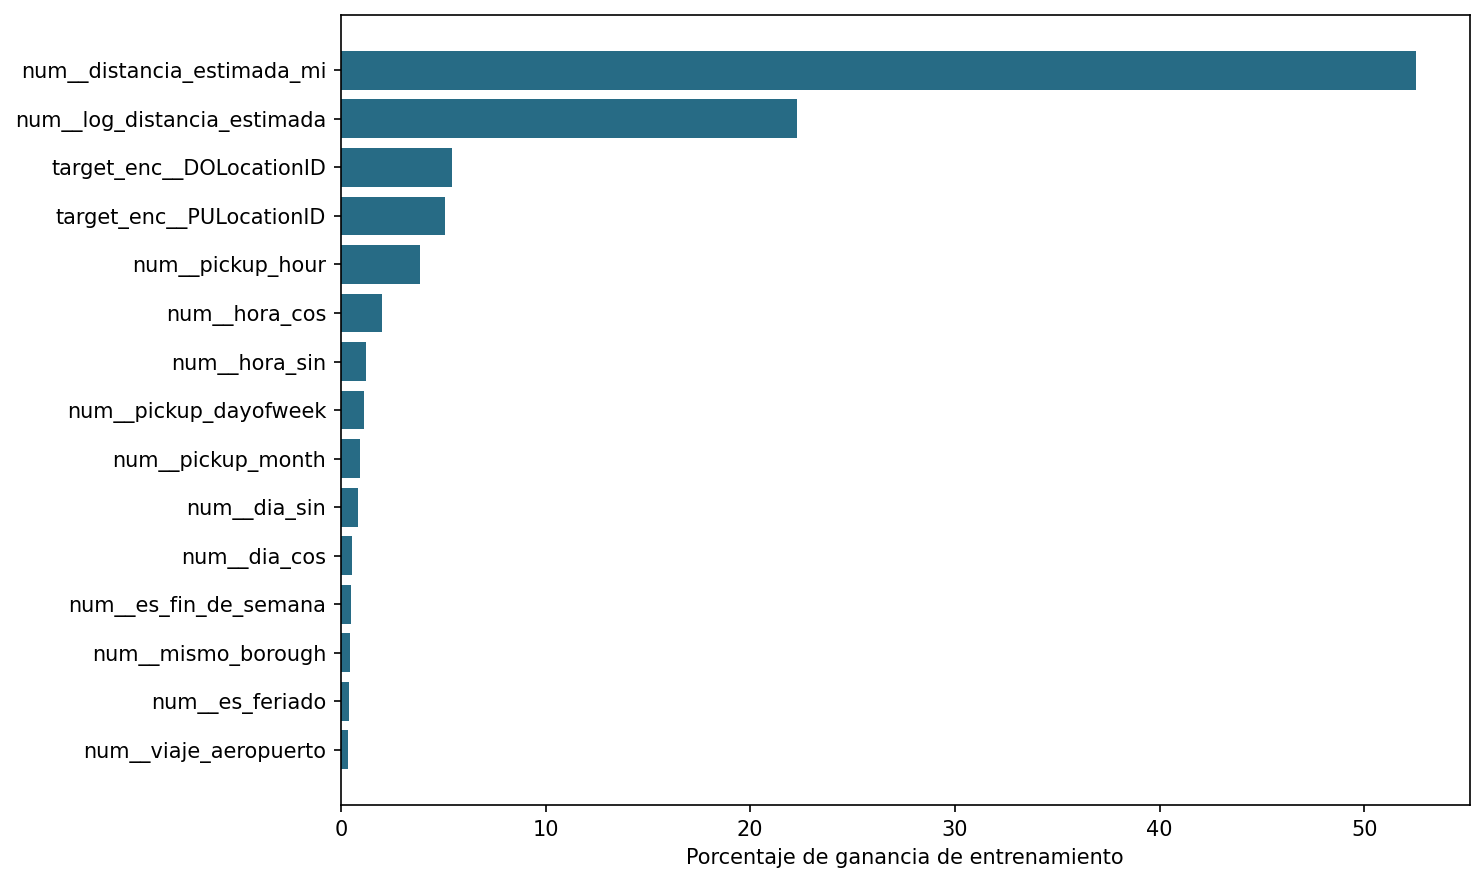

02_importancia_shap.png


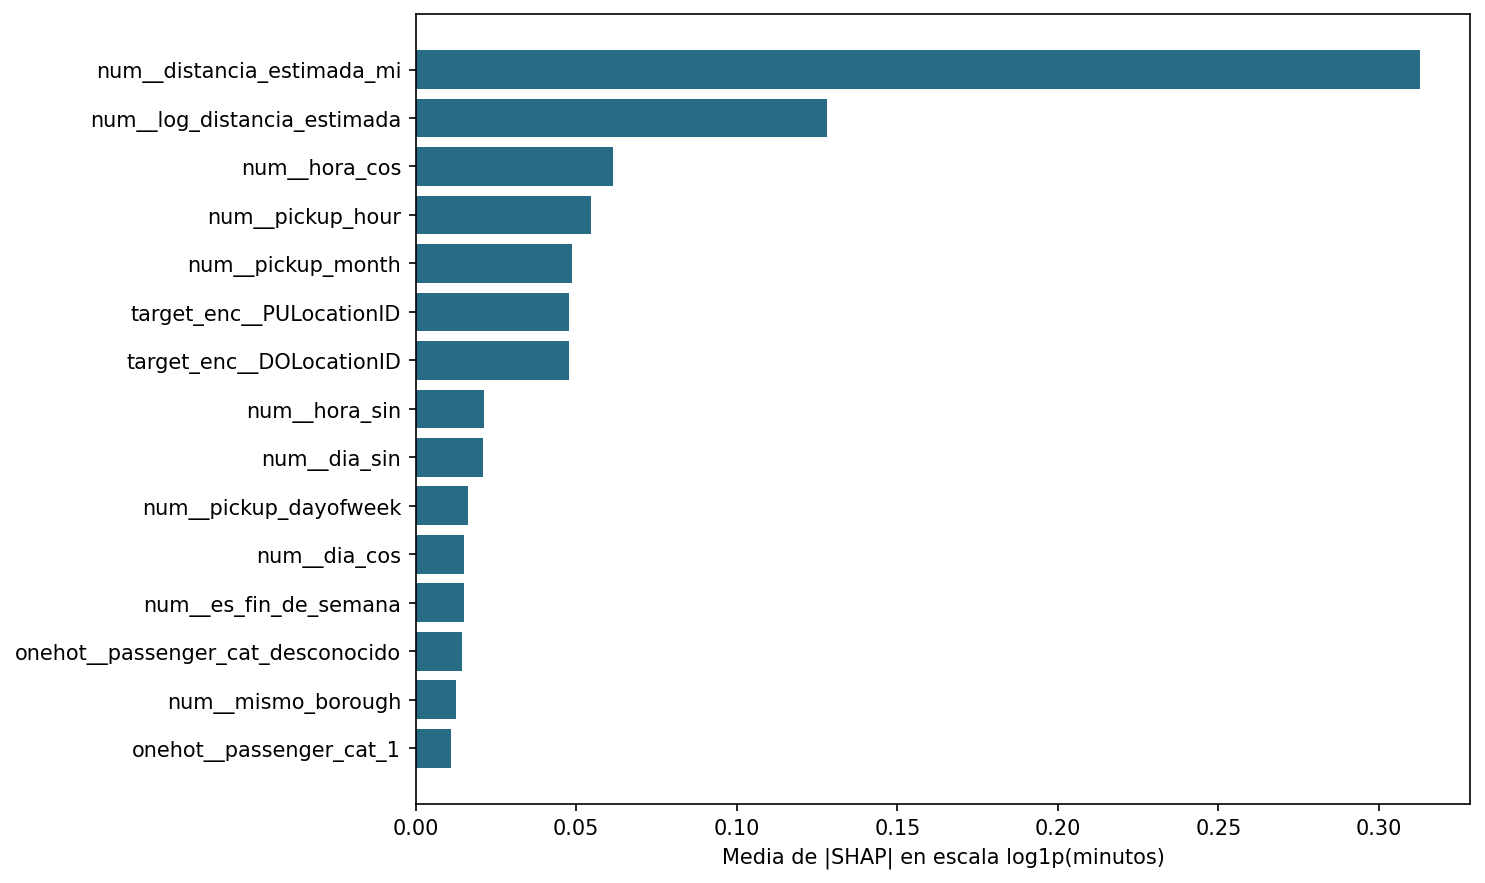

03_shap_distribucion.png


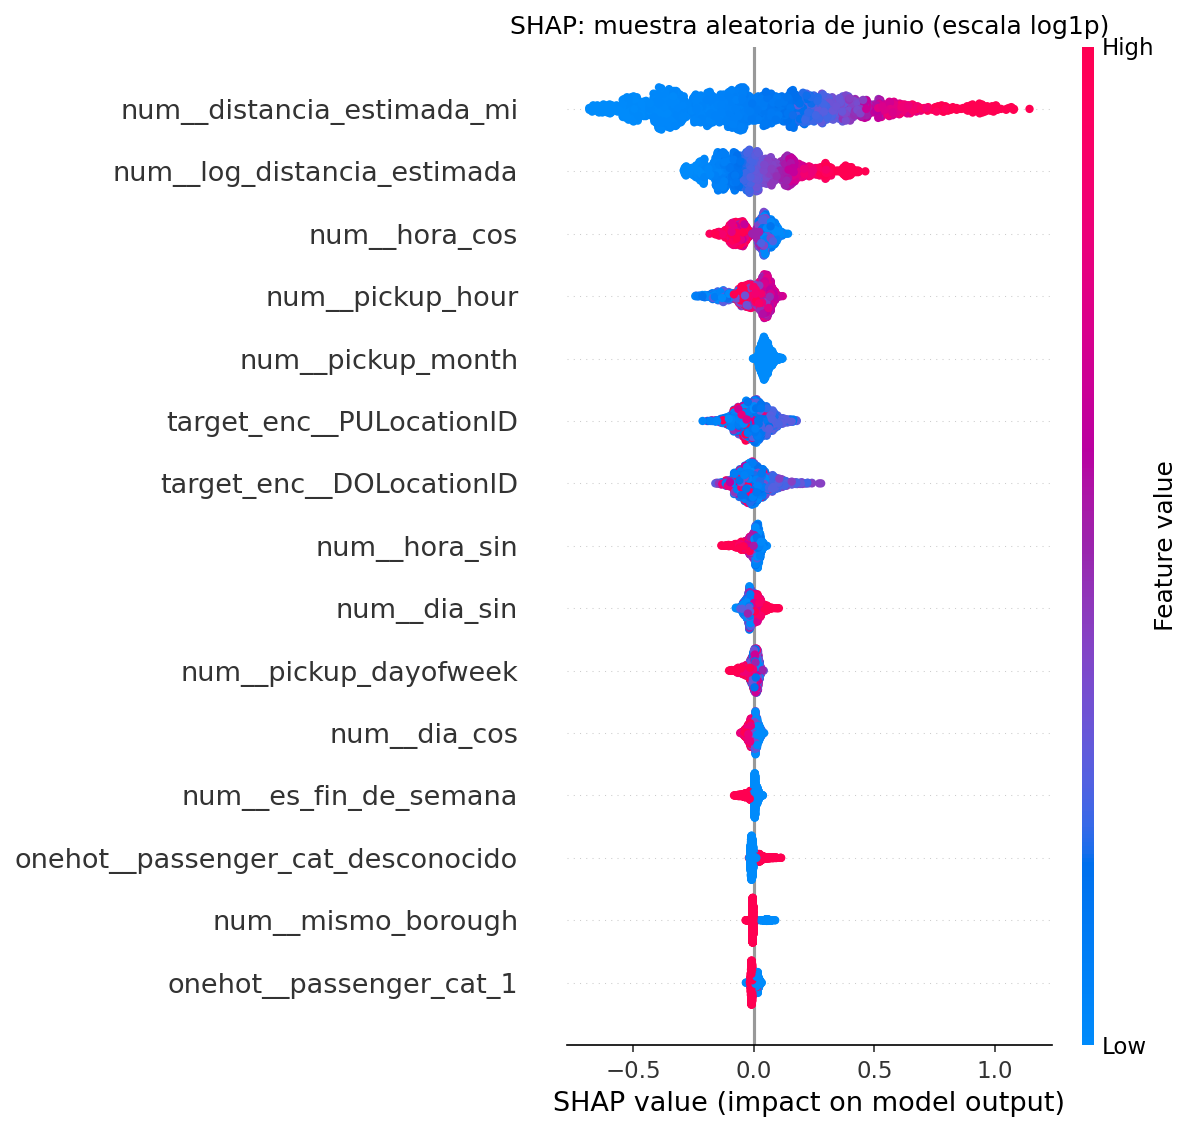

04_dependencia_distancia.png


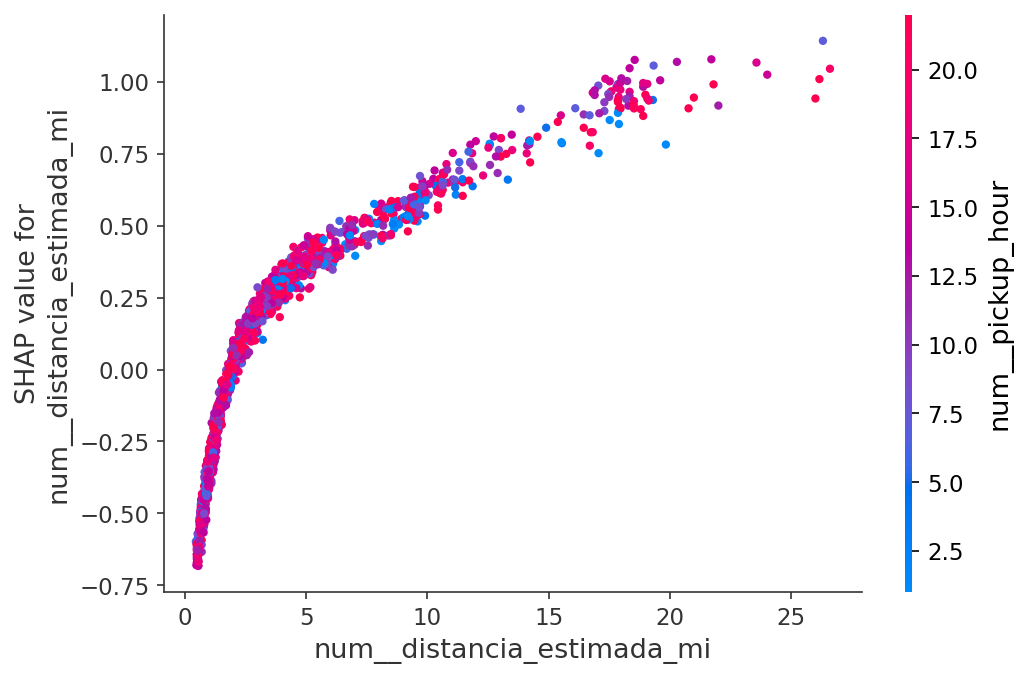

05_dependencia_hora.png


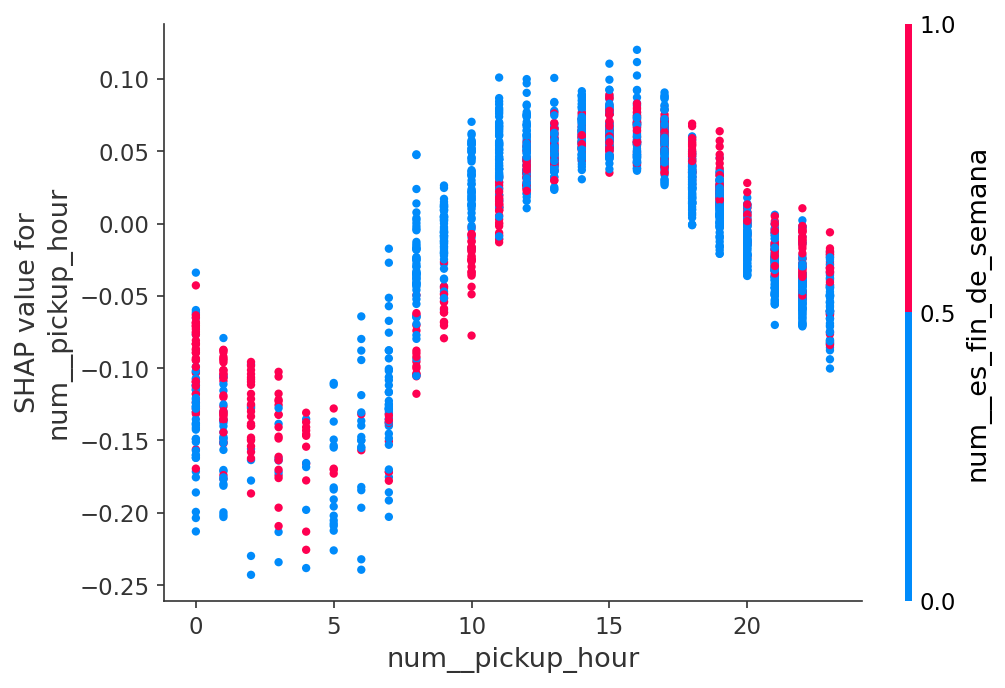

06_caso_error_mediano.png


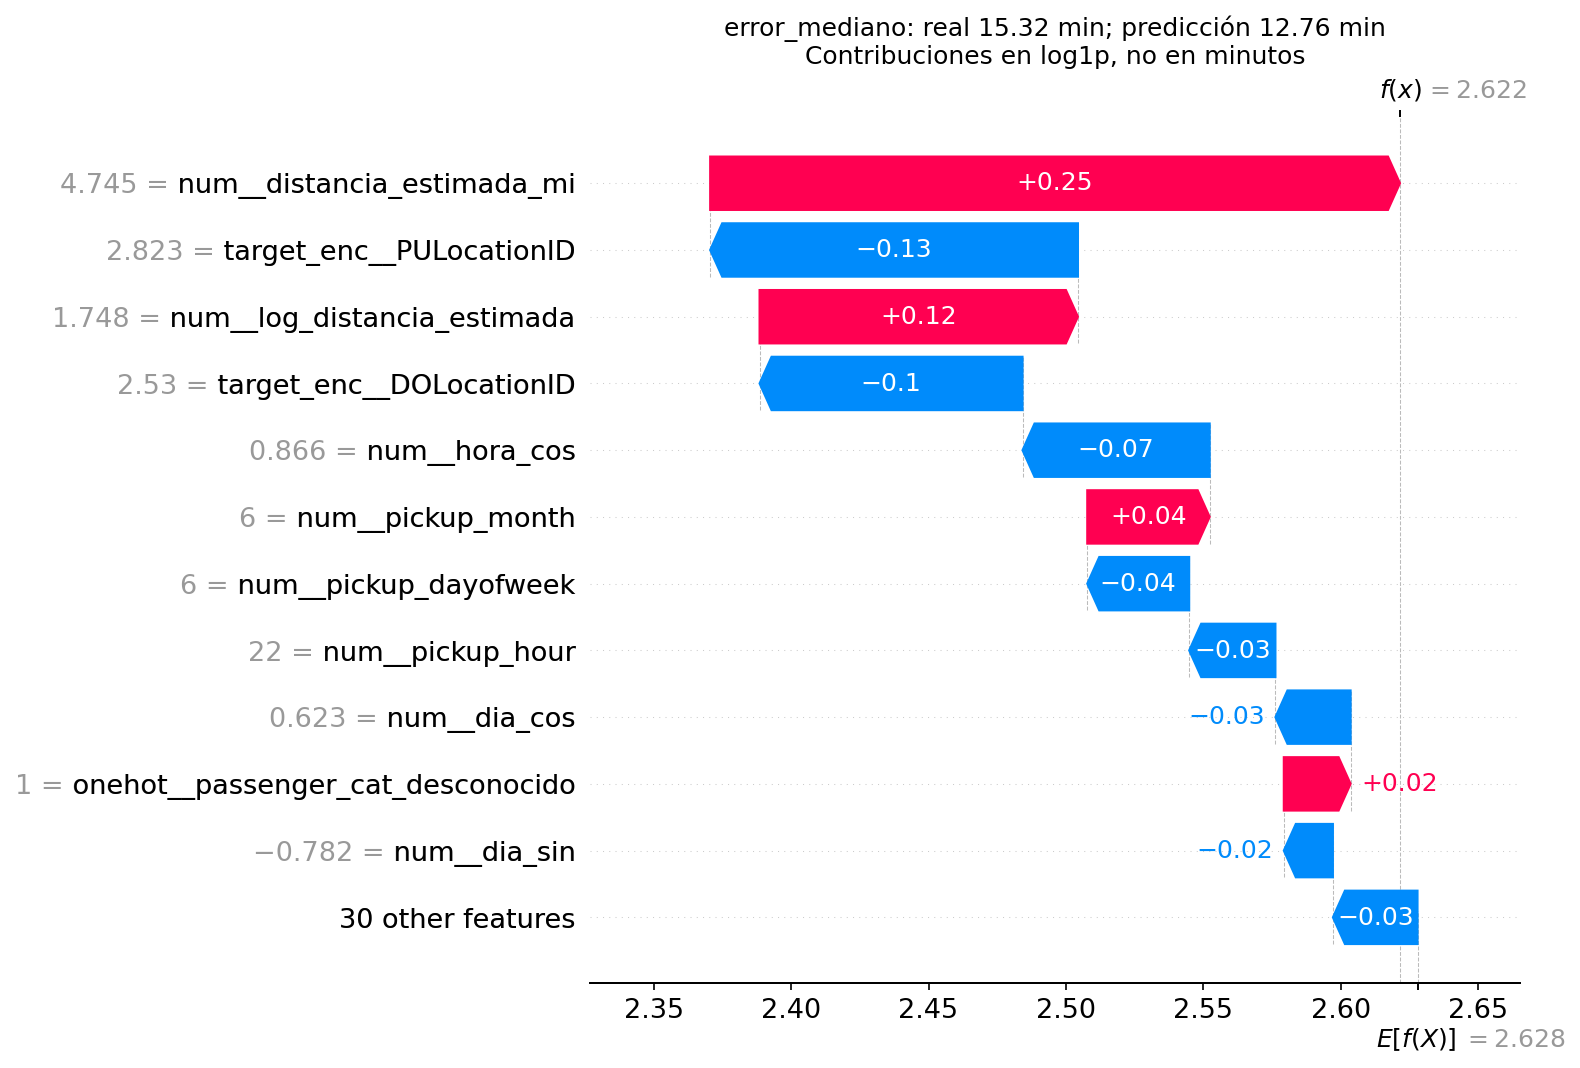

06_caso_mayor_error.png


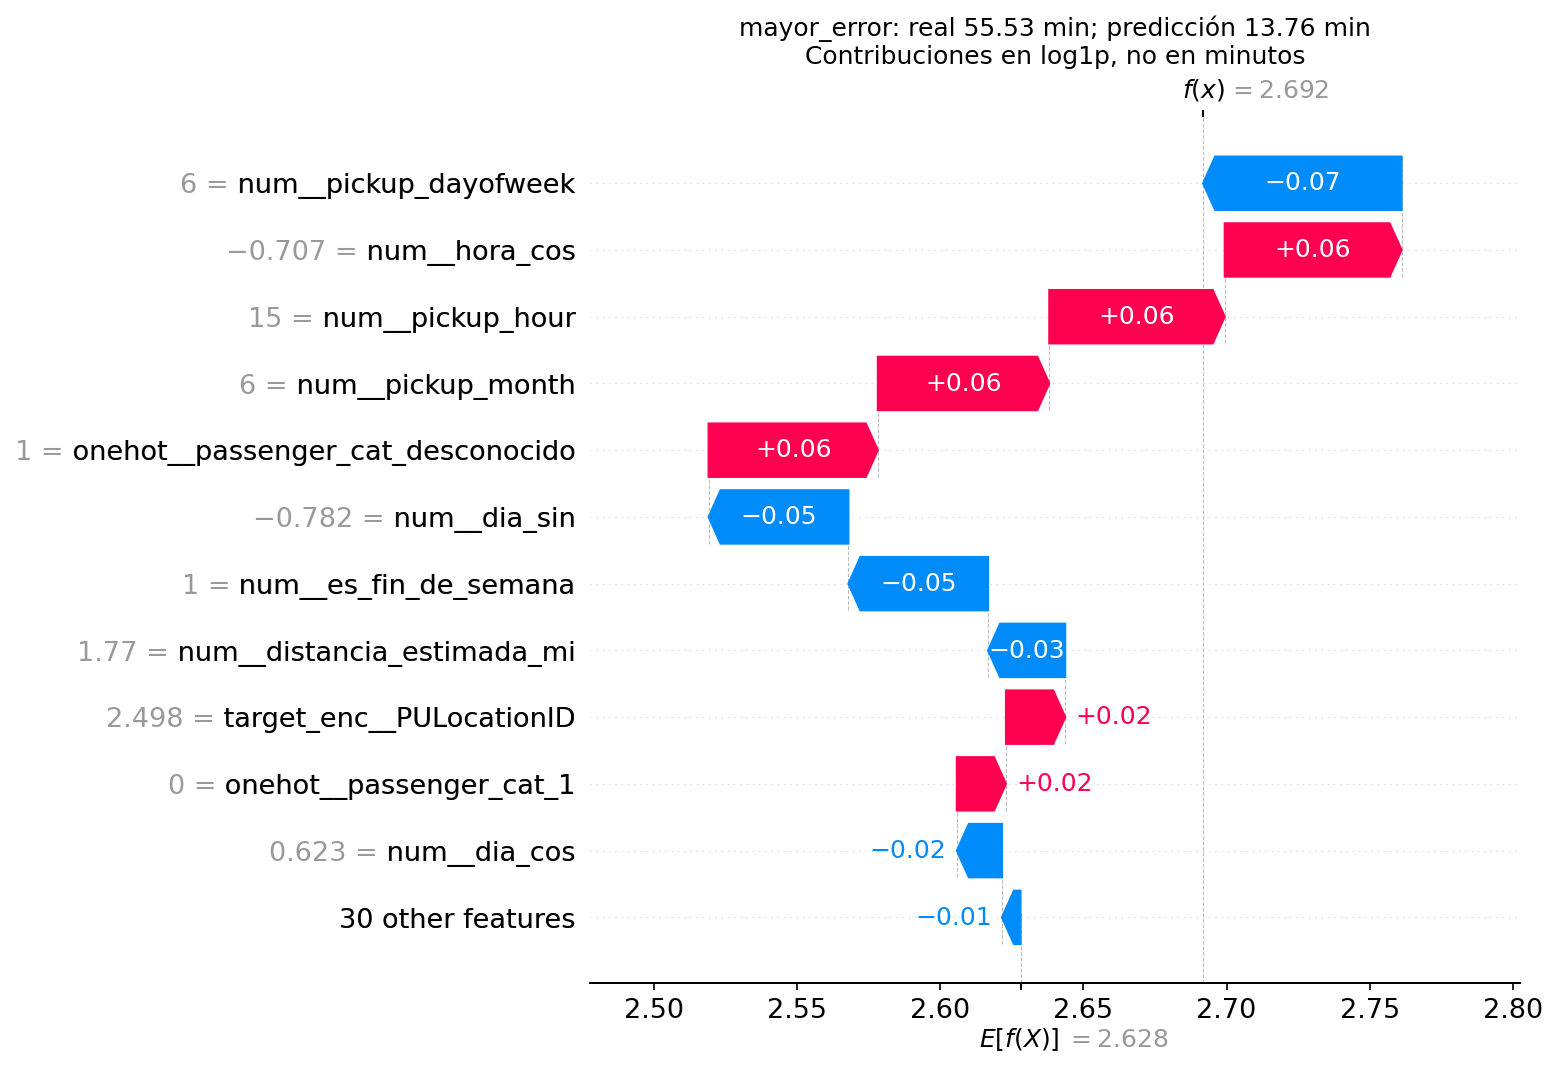

06_caso_menor_error.png


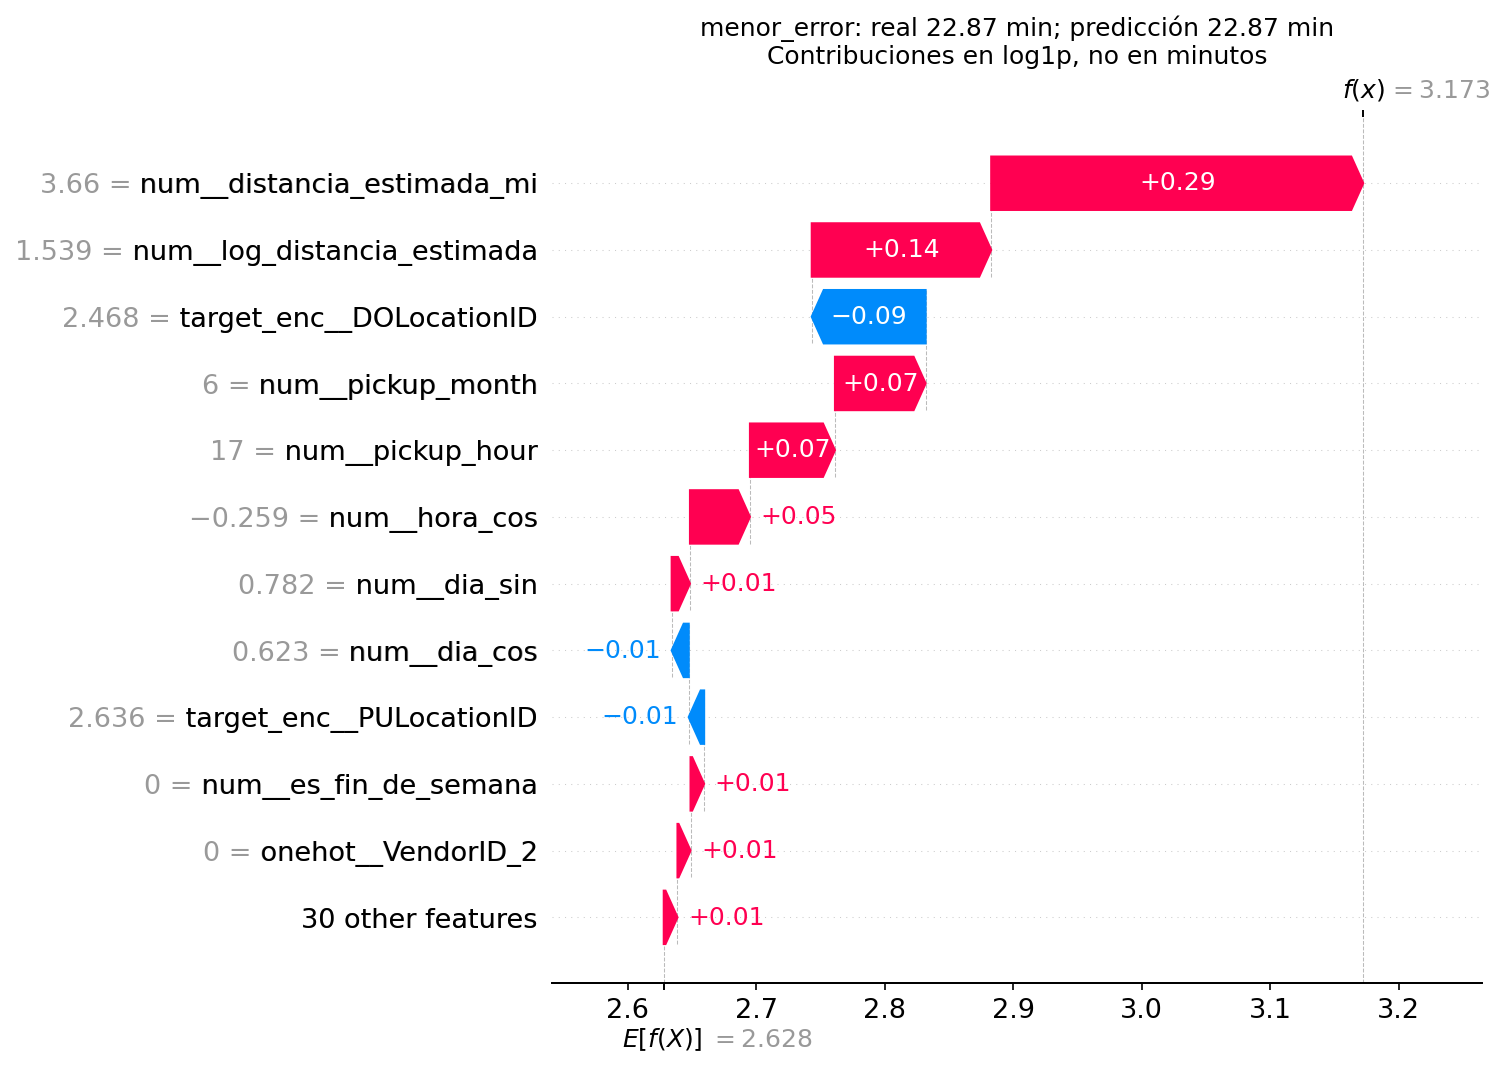

# Semana 13: interpretabilidad, sesgos y limitaciones

## Alcance y procedencia

Análisis nuevo desde la configuración de semana 12. No se leen ni reutilizan las
figuras o estadísticas del notebook 06 eliminado. Se usan registros reales de NYC
Yellow Taxi (enero-junio de 2025), la limpieza de `src/data.py` y las variables de
`src/features.py`. Entrenamiento: 9,319,633 viajes de enero-mayo;
test: 2,008,054 de junio. Ambos conservan el muestreo mensual
del 50 % y semilla 42. La configuración de LightGBM conserva sus 1710 árboles.

El preprocesamiento por bloques conserva float64 y el cross-fitting de
TargetEncoder. Se compara con el pipeline original sobre 3000 filas reales antes
del entrenamiento completo. Esta comprobación técnica no es una evaluación predictiva.

## Control de reproducción

- MAE reconstruido: 3.693972 minutos.
- RMSLE reconstruido: 0.306646.
- Diferencia MAE frente a semana 12: +0.000000 minutos.
- Diferencia RMSLE: +0.000000.

Los límites de control se fijaron antes de evaluar: 0.02 minutos de MAE y 0.002
de RMSLE. No son intervalos de confianza ni prueban identidad entre los modelos.
No se archivaron todas las versiones ni hashes de los datos de la ejecución de
semana 12; esta ejecución sí los registra. Junio se usa para verificar y describir
el modelo congelado, nunca para seleccionar hiperparámetros o variables nuevas.

## Importancia global

SHAP se calcula en 2,000 viajes seleccionados al azar, sin reemplazo,
del test de junio, con semilla 42. El entrenamiento usa todas las
filas indicadas arriba. La muestra SHAP solo reduce el costo de explicar predicciones;
no garantiza cobertura suficiente de rutas raras.

| feature | mean_abs_shap_log1p | gain_pct |
| --- | --- | --- |
| num__distancia_estimada_mi | 0.312823 | 52.516179 |
| num__log_distancia_estimada | 0.128189 | 22.292732 |
| num__hora_cos | 0.061433 | 2.032984 |
| num__pickup_hour | 0.054683 | 3.880828 |
| num__pickup_month | 0.04882 | 0.940246 |
| target_enc__PULocationID | 0.047862 | 5.074294 |
| target_enc__DOLocationID | 0.047614 | 5.419307 |
| num__hora_sin | 0.021116 | 1.227957 |
| num__dia_sin | 0.020943 | 0.855743 |
| num__pickup_dayofweek | 0.016375 | 1.142038 |
| num__dia_cos | 0.014982 | 0.558468 |
| num__es_fin_de_semana | 0.014961 | 0.518058 |
| onehot__passenger_cat_desconocido | 0.014423 | 0.32545 |
| num__mismo_borough | 0.012645 | 0.451648 |
| onehot__passenger_cat_1 | 0.010924 | 0.216529 |

Gain es la importancia acumulada en los splits del entrenamiento; no representa un
porcentaje de mejora del MAE de test. `mean_abs_shap_log1p` mide magnitud de contribución
al modelo en escala log1p. Ninguna de las dos medidas demuestra causalidad.

El método es TreeSHAP `tree_path_dependent`, con salida `raw`. Las contribuciones
explican log(1 + duración), no minutos. Se verifica base + suma(SHAP) = salida del
modelo; error máximo observado: 7.55e-14.
La transformación inversa se aplica a la suma completa. No se aplica `expm1` a cada
contribución por separado para sumarla en minutos. La base transformada tampoco
equivale a la duración media de los viajes.

Las variables de distancia y su logaritmo son redundantes, y existen varias
codificaciones de hora y zona. Esa dependencia puede repartir la importancia entre
columnas; una posición en el ranking no equivale a una contribución causal aislada.
Los gráficos de dependencia coloreados sugieren patrones del modelo, pero no prueban
una interacción causal ni sustituyen el cálculo de valores SHAP de interacción.

## Ejemplos individuales

Se seleccionan el menor error, el error mediano y el mayor error absoluto dentro
de la muestra SHAP. Son casos ilustrativos elegidos por su error, no una muestra
representativa adicional ni evidencia de un sesgo sistemático.

| criterio | posicion_test | fila_archivo | real_min | pred_min | error_firmado |
| --- | --- | --- | --- | --- | --- |
| menor_error | 1342885 | 1741025 | 22.8667 | 22.8672 | 0.0005 |
| error_mediano | 1417339 | 3724593 | 15.3167 | 12.758 | -2.5586 |
| mayor_error | 1310628 | 3439373 | 55.5333 | 13.7584 | -41.775 |

Las figuras waterfall muestran contribuciones en log1p. Los errores residuales
no permiten atribuir el resultado a congestión, clima o incidentes no observados.

## Cobertura geográfica y errores

Estas tablas se calculan sobre todo el test de junio, no solo la muestra SHAP.
`error_medio_firmado` = predicción menos duración real: negativo indica subestimación
media en el grupo observado, positivo sobreestimación media. `fraccion_subestimada`
es la proporción de viajes con predicción inferior a la duración real. Un MAE alto
por sí solo no identifica la dirección del error. Se informa n y cobertura para
no interpretar grupos pequeños como evidencia concluyente.

### Borough de origen

| grupo | n | MAE | error_medio_firmado | fraccion_subestimada | porcentaje_test |
| --- | --- | --- | --- | --- | --- |
| Bronx | 16961 | 6.2017 | -0.649 | 0.4752 | 0.8446 |
| Brooklyn | 88463 | 5.107 | -0.6387 | 0.4871 | 4.4054 |
| EWR | 15 | 11.6567 | -7.7259 | 0.6 | 0.0007 |
| Manhattan | 1707492 | 3.3273 | -0.2479 | 0.456 | 85.0322 |
| Queens | 194919 | 6.0399 | -0.6227 | 0.477 | 9.7069 |
| Staten Island | 204 | 9.7786 | -3.7657 | 0.5735 | 0.0102 |

### Viajes con origen o destino en un aeropuerto

| grupo | n | MAE | error_medio_firmado | fraccion_subestimada | porcentaje_test |
| --- | --- | --- | --- | --- | --- |
| False | 1838027 | 3.4338 | -0.2693 | 0.4584 | 91.5327 |
| True | 170027 | 6.5061 | -0.6946 | 0.4731 | 8.4673 |

### Disponibilidad del número de pasajeros

| grupo | n | MAE | error_medio_firmado | fraccion_subestimada | porcentaje_test |
| --- | --- | --- | --- | --- | --- |
| False | 1450615 | 3.7699 | -0.3282 | 0.4573 | 72.2398 |
| True | 557439 | 3.4964 | -0.2456 | 0.4655 | 27.7602 |

Las diferencias entre estos grupos son descriptivas y pueden reflejar diferencias
en rutas, horarios o duración. No prueban discriminación causal ni la causa de los
datos faltantes. No se afirma una relación con `payment_type`, que no se analiza aquí.

## Limitaciones y riesgos de uso

- El alcance es taxi amarillo y el periodo observado; no está demostrada la
  generalización a otras flotas, ciudades o estaciones del año.
- La limpieza elimina duraciones fuera de 1–180 minutos, zonas 264/265, distancias
  no positivas y velocidades mayores a 80 mph, entre otras reglas. Las métricas
  describen el conjunto retenido, no todos los viajes crudos o futuros.
- La distancia usada por el modelo es una mediana histórica por ruta, aprendida
  solo en entrenamiento, con respaldo por origen y mediana global. No es distancia
  entre centroides ni la distancia real del viaje de test. Los tramos de distancia
  real del CSV de errores son análisis posterior, no variables predictoras.
- La inferencia requiere conocer el destino declarado al recojo. Las zonas no
  identifican direcciones exactas ni condiciones de tráfico en vivo.
- Los seis meses no permiten caracterizar un ciclo anual completo. `pickup_month`
  no aprende una tendencia extrapolable por tener un valor SHAP distinto de cero;
  junio no estuvo en entrenamiento.
- El TargetEncoder conserva el cross-fitting interno de cinco folds del proyecto.
  Esa partición interna no es temporal estricta, aunque el test junio permanece
  separado del ajuste. Debe distinguirse de la validación temporal externa.
- Las predicciones son estimaciones puntuales. No se han calibrado intervalos ni
  validado decisiones de asignación de flota o garantías de llegada. Su uso como
  garantía puede perjudicar a usuarios o conductores ante errores grandes.
- Futuro trabajo: validación en meses posteriores, auditoría de rutas poco
  frecuentes, evaluación de incertidumbre y de datos de tráfico disponibles al
  recojo. Estas propuestas no se presentan como mejoras ya verificadas.

## Evidencia y reproducción

Ejecutar `notebooks/06_interpretabilidad.ipynb` con `requirements.txt`.
Los resultados de esta ejecución están en `outputs/semana13/` y las figuras en
`reports/semana13/figures/`. El modelo y el preprocesador se guardan en el directorio
de Drive indicado por el notebook. El archivo `modelo_metadata.json` registra
configuración, versiones y hashes. Las tablas completas están en
`importancias.csv`, `errores_segmentos.csv` y `casos_locales.csv`.

La redacción interpretativa adicional deberá contrastarse con las figuras nuevas;
no se trasladan conclusiones numéricas de la ejecución descartada.


In [10]:
from IPython.display import display, Image, Markdown

informe = escribir_informe(
    REPORT_DIR / 'informe_semana13.md', verificacion, importancias,
    metadata_shap, segmentos, metadata_modelo,
)
shutil.copytree(OUTPUT_DIR, DRIVE_DIR / 'resultados/outputs/semana13', dirs_exist_ok=True)
shutil.copytree(REPORT_DIR, DRIVE_DIR / 'resultados/reports/semana13', dirs_exist_ok=True)
for path in sorted(FIGURES_DIR.glob('*.png')):
    print(path.name)
    display(Image(filename=str(path)))
display(Markdown(informe.read_text(encoding='utf-8')))

## 10. Descargar resultados para GitHub
Este ZIP contiene únicamente los resultados e informe nuevos, con sus rutas. No incluye los Parquet
crudos ni el modelo. Extrae el ZIP en tu computadora y sube sus archivos a la rama `semana-13`.
Además, guarda/descarga este notebook con sus salidas y actualiza `notebooks/06_interpretabilidad.ipynb`.

Commit del código: `Semana 13: implementar reconstrucción e interpretabilidad desde semana 12`.
Commit después de revisar la ejecución: `Semana 13: añadir resultados SHAP, sesgos y limitaciones`.
No marques la semana como ejecutada antes de completar las secciones 5–9.

In [11]:
import zipfile
from google.colab import files

archive = Path('/content/semana13_resultados.zip')
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
    for folder in [OUTPUT_DIR, REPORT_DIR]:
        for path in sorted(folder.rglob('*')):
            if path.is_file():
                z.write(path, path.relative_to(REPO_DIR))
files.download(str(archive))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>